# 3 · Predict: from the surface to 1,000 m with the course's regression methods

**Syllabus:** Module 4 (linear, multiple and polynomial regression, KNN, decision trees,
model evaluation).

**Task:** given the 8 satellite measurements of a patch of ocean on one day, plus where
it is and what day of the year it is, predict the temperature at 15 depths from 0 to
1,000 m.

**The rules of a fair test:**

1. **Split by time, never at random.** Neighbouring days are nearly identical, so a
   random split would let a model "remember" tomorrow from today. We train on
   2010–2020, tune on 2021–2022 (validation) and test once on 2023–2024.
2. **Settings (k, tree depth, polynomial degree) are chosen on the validation years
   only.** The test years are touched once, at the end.
3. **The final judge is real Argo floats**, the 6,144 held-out casts that Satelight's
   deep models are scored on, at exactly the same points. Every model in the final table
   is compared on the same measurements.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeRegressor
import seaborn as sns
import common as C

C.style()
cells = C.load_cells()
casts = C.load_casts()
for d in (cells, casts):
    d["log_bathy"] = np.log10(d["bathy"].clip(lower=1))
FEATURES = C.INPUTS + ["lat", "lon", "log_bathy", "doy_sin", "doy_cos"]
train, val, test = (cells[cells["split"] == s] for s in ("train", "val", "test"))
print({k: len(v) for k, v in [("train", train), ("val", val), ("test", test), ("Argo casts", casts)]})

{'train': 159360, 'val': 26720, 'test': 28560, 'Argo casts': 6144}


## 3.1 The methods

| Method | Idea in one line |
|---|---|
| **Simple linear regression** | A straight line from sea surface temperature alone |
| **Multiple linear regression** | A weighted sum of all 13 inputs, one formula for the whole ocean |
| **Polynomial regression** | The same, plus squares and products of the inputs, so curves and interactions can be learned |
| **KNN regression** | Find the k most similar patches in the training years and average their temperatures |
| **Decision tree** | A flowchart of yes/no questions on the inputs ("is SST > 28.6?") ending in a temperature |

Each method gets one model per depth (15 models), trained on the patches where that
depth exists. Inputs are standardised (mean 0, std 1) with statistics from the training
years only. KNN needs this, because it measures distances.

KNN is the exception to "one model per depth": a patch's nearest neighbours depend only
on the inputs, not on the depth being predicted, so one neighbour search serves all 15
depths. At each depth the neighbours without water there (shallow sea) are skipped.
The result is the same as 15 separate distance-weighted KNN regressors, at a fifteenth
of the cost.

In [2]:
class KNNAllDepths:
    def __init__(self, k):
        self.k = k

    def fit(self, data):
        self.scaler = StandardScaler().fit(data[FEATURES].to_numpy())
        self.nn = NearestNeighbors().fit(self.scaler.transform(data[FEATURES].to_numpy()))
        self.Y = data[C.TARGETS].to_numpy()
        return self

    def neighbours(self, X, k):
        return self.nn.kneighbors(self.scaler.transform(X[FEATURES].to_numpy()), n_neighbors=k)

    def average(self, dist, idx):
        w = (1 / np.maximum(dist, 1e-9))[..., None]          # closer neighbours count more
        y = self.Y[idx]                                       # (rows, k, 15)
        ok = np.isfinite(y)
        with np.errstate(invalid="ignore"):
            return (np.where(ok, y, 0) * w).sum(1) / (ok * w).sum(1)

    def predict(self, X):
        return self.average(*self.neighbours(X, self.k))


def make(method, param=None):
    if method in ("simple", "multiple"):
        return make_pipeline(StandardScaler(), LinearRegression())
    if method == "polynomial":
        return make_pipeline(StandardScaler(), PolynomialFeatures(param, include_bias=False), StandardScaler(), LinearRegression())
    if method == "tree":
        return make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=param, min_samples_leaf=20, random_state=C.SEED))


def cols_for(method):
    return ["sst"] if method == "simple" else FEATURES


def fit_all(method, param=None, data=train):
    if method == "knn":
        return KNNAllDepths(param).fit(data)
    models = {}
    for tcol in C.TARGETS:
        d = data.dropna(subset=[tcol])
        models[tcol] = make(method, param).fit(d[cols_for(method)].to_numpy(), d[tcol].to_numpy())
    return models


def predict_all(models, method, X: pd.DataFrame):
    out = np.full((len(X), len(C.TARGETS)), np.nan)
    ok = X[cols_for(method)].notna().all(axis=1).to_numpy()
    if method == "knn":
        out[ok] = models.predict(X.loc[ok])
        return out
    for k, tcol in enumerate(C.TARGETS):
        out[ok, k] = models[tcol].predict(X.loc[ok, cols_for(method)].to_numpy())
    return out


def rmse_by_depth(pred, truth):
    err = pred - truth
    return np.sqrt(np.nanmean(err ** 2, axis=0))

## 3.2 Choosing settings on the validation years

Each candidate setting is trained on 2010–2020 and scored on 2021–2022 against
GLORYS. The setting with the lowest mean RMSE over the 15 depths wins. The test years
play no part in this.

In [3]:
grid = {"polynomial": [2, 3], "knn": [5, 10, 20, 50, 100], "tree": [6, 10, 14, 18, 24]}
y_val = val[C.TARGETS].to_numpy()
tuning = []
for method, params in grid.items():
    if method == "knn":                       # one search with the largest k; smaller k are its first columns
        t0 = time.time()
        knn = fit_all("knn", max(params))
        dist, idx = knn.neighbours(val, max(params))
        for p in params:
            score = float(np.mean(rmse_by_depth(knn.average(dist[:, :p], idx[:, :p]), y_val)))
            tuning.append({"method": method, "setting": p, "val_rmse_mean": round(score, 4), "seconds": round(time.time() - t0, 1)})
            print(tuning[-1], flush=True)
        continue
    for p in params:
        t0 = time.time()
        m = fit_all(method, p)
        score = float(np.mean(rmse_by_depth(predict_all(m, method, val), y_val)))
        tuning.append({"method": method, "setting": p, "val_rmse_mean": round(score, 4), "seconds": round(time.time() - t0, 1)})
        print(tuning[-1], flush=True)
tuning = pd.DataFrame(tuning)
best = tuning.loc[tuning.groupby("method")["val_rmse_mean"].idxmin()].set_index("method")["setting"].to_dict()
C.record("regression.tuning", tuning.to_dict("records"))
C.record("regression.chosen", best)
best

{'method': 'polynomial', 'setting': 2, 'val_rmse_mean': 0.7082, 'seconds': 10.4}


{'method': 'polynomial', 'setting': 3, 'val_rmse_mean': 0.6798, 'seconds': 88.0}


{'method': 'knn', 'setting': 5, 'val_rmse_mean': 0.7455, 'seconds': 15.6}


{'method': 'knn', 'setting': 10, 'val_rmse_mean': 0.7167, 'seconds': 15.7}


{'method': 'knn', 'setting': 20, 'val_rmse_mean': 0.7046, 'seconds': 15.8}


...

{'method': 'tree', 'setting': 10, 'val_rmse_mean': 0.7358, 'seconds': 13.5}


{'method': 'tree', 'setting': 14, 'val_rmse_mean': 0.7316, 'seconds': 16.9}


{'method': 'tree', 'setting': 18, 'val_rmse_mean': 0.7391, 'seconds': 18.4}


{'method': 'tree', 'setting': 24, 'val_rmse_mean': 0.7414, 'seconds': 18.4}


{'knn': 20, 'polynomial': 3, 'tree': 14}

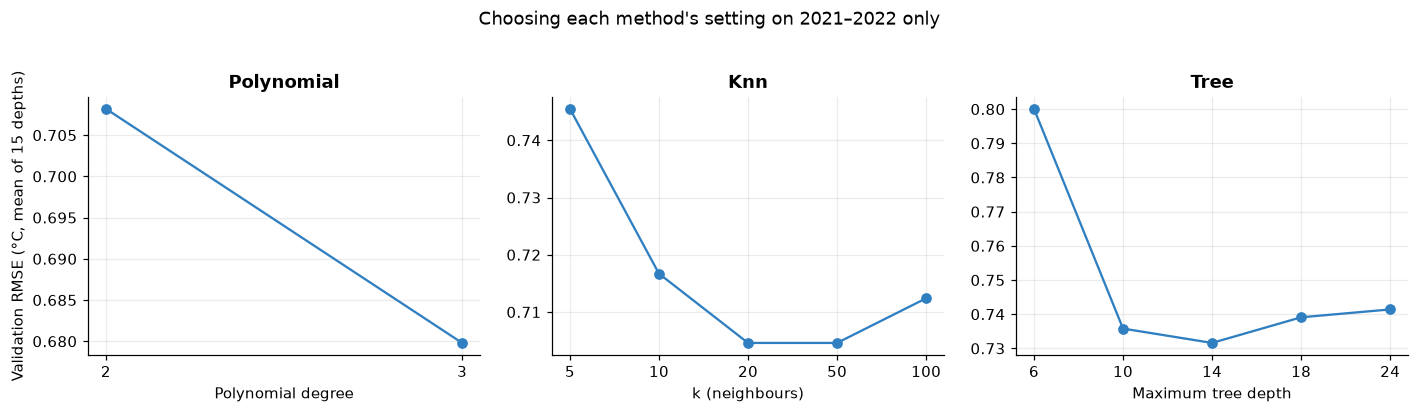

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (method, label) in zip(axes, [("polynomial", "Polynomial degree"), ("knn", "k (neighbours)"), ("tree", "Maximum tree depth")]):
    t = tuning[tuning["method"] == method]
    ax.plot(t["setting"].astype(str), t["val_rmse_mean"], marker="o", color=C.PALETTE["course"])
    ax.set_xlabel(label); ax.set_title(method.capitalize())
axes[0].set_ylabel("Validation RMSE (°C, mean of 15 depths)")
fig.suptitle("Choosing each method's setting on 2021–2022 only", y=1.03)
fig.tight_layout(); C.save(fig, "regression_tuning")

Too simple a model underfits and too flexible a model overfits. A deep tree memorises
the training years and does worse on new ones, and KNN with very few neighbours copies
noise. The validation curve shows where each method balances the two.

## 3.3 The test: real Argo floats, 2023–2024

In [5]:
LABELS = {"simple": "Simple linear (SST only)", "multiple": "Multiple linear", "polynomial": "Polynomial",
          "knn": "KNN", "tree": "Decision tree"}
course, fitted = {}, {}
for method in LABELS:
    fitted[method] = m = fit_all(method, best.get(method))
    course[LABELS[method]] = {"argo": predict_all(m, method, casts), "glorys_test": predict_all(m, method, test)}

saved = casts[["cast_id"]].copy()
for name, v in course.items():
    for k, d in enumerate(C.DEPTHS):
        saved[f"{name}|t{d}"] = v["argo"][:, k]
saved.to_csv(C.ROOT / "results" / "course_predictions_argo.csv.gz", index=False, float_format="%.3f")

obs = C.profiles(casts, "obs_")
P4 = {"Climatology (floor)": "climatology|", "Satelight per-cell ridge": "linear|",
      "Satelight U-Net": "unet|", "Satelight hybrid": "hybrid (selected)|", "GLORYS (ceiling)": "GLORYS (ceiling)|"}
satelight = {k: C.profiles(casts, v) for k, v in P4.items()}
all_contenders = {"Satelight": [c for c in casts.columns if "|" in c]}

# Satelight's own rule: a (cast, depth) counts only where the cast and every Satelight contender have a value.
p4_cols = sorted({c.split("|")[0] for c in all_contenders["Satelight"]})
common = np.isfinite(obs)
for name in p4_cols:
    common &= np.isfinite(C.profiles(casts, f"{name}|"))
missing_course = {k: int((common & ~np.isfinite(v["argo"])).sum()) for k, v in course.items()}
print("Satelight scoring points:", int(common.sum()), "| points a course model could not predict:", missing_course)
C.record("regression.argo_points", int(common.sum()))
C.record("regression.points_unpredicted", missing_course)

Satelight scoring points: 88829 | points a course model could not predict: {'Simple linear (SST only)': 0, 'Multiple linear': 0, 'Polynomial': 0, 'KNN': 0, 'Decision tree': 0}


In [6]:
contenders = {**{k: v for k, v in satelight.items()}, **{k: v["argo"] for k, v in course.items()}}
pts = common.copy()
for v in contenders.values():
    pts &= np.isfinite(v)


def table(region_mask):
    rows = {}
    for name, pred in contenders.items():
        r = []
        for k in range(15):
            sel = pts[:, k] & region_mask
            r.append(np.sqrt(np.mean((pred[sel, k] - obs[sel, k]) ** 2)))
        rows[name] = r
    return pd.DataFrame(rows, index=C.DEPTHS).T


regions = {"North Indian Ocean": np.ones(len(casts), bool), "Bay of Bengal": casts["basin"].eq("Bay of Bengal").to_numpy(),
           "Arabian Sea": casts["basin"].eq("Arabian Sea").to_numpy()}
tables = {r: table(m) for r, m in regions.items()}
check = tables["North Indian Ocean"].loc[["Climatology (floor)", "Satelight hybrid"], [0, 1000]].round(3)
print("Reproduces Satelight's published table (0.869, 0.543 at 0 m; 0.308, 0.328 at 1,000 m):\n", check)
tables["North Indian Ocean"].round(3)

Reproduces Satelight's published table (0.869, 0.543 at 0 m; 0.308, 0.328 at 1,000 m):
                       0      1000
Climatology (floor)  0.869  0.308
Satelight hybrid     0.543  0.328


,0,5,10,20,30,50,75,100,125,150,200,300,500,700,1000
Climatology (floor),0.869,0.883,0.927,1.055,1.194,1.383,1.689,1.865,1.680,1.365,0.921,0.624,0.396,0.377,0.308
Satelight per-cell ridge,1.127,1.142,1.186,1.305,1.429,1.542,1.592,1.699,1.527,1.249,0.971,0.723,0.543,0.500,0.390
Satelight U-Net,0.545,0.537,0.636,0.837,0.976,1.124,1.338,1.567,1.429,1.130,0.795,0.602,0.386,0.356,0.320
Satelight hybrid,0.543,0.542,0.629,0.825,0.976,1.131,1.342,1.587,1.449,1.140,0.796,0.609,0.392,0.359,0.328
GLORYS (ceiling),0.434,0.411,0.516,0.679,0.831,0.980,1.179,1.281,1.158,0.919,0.677,0.503,0.344,0.355,0.336
Simple linear (SST only),0.423,0.407,0.592,1.194,1.737,2.449,2.761,2.562,2.236,2.111,2.163,1.893,1.511,1.476,1.112
Multiple linear,0.433,0.417,0.585,1.053,1.350,1.538,1.701,1.810,1.647,1.357,0.986,0.728,0.590,0.617,0.483
Polynomial,0.476,0.476,0.583,0.831,1.000,1.153,1.365,1.575,1.452,1.159,0.810,0.606,0.423,0.398,0.332
KNN,0.583,0.590,0.669,0.897,1.074,1.201,1.443,1.653,1.495,1.177,0.841,0.665,0.447,0.425,0.339
Decision tree,0.488,0.488,0.612,0.870,1.116,1.224,1.454,1.669,1.555,1.243,0.863,0.625,0.422,0.384,0.329


The first check matters: on the same points, our scoring code gives back exactly the
numbers Satelight published. Any difference in the rest of the table therefore comes
from the models, not from the scoring.

In [7]:
order = list(contenders)
summ = pd.DataFrame({r: t.mean(axis=1) for r, t in tables.items()}).loc[order]
clim, ceil = summ.loc["Climatology (floor)"], summ.loc["GLORYS (ceiling)"]
summ_gap = ((clim - summ) / (clim - ceil) * 100).round(0)
summary = pd.concat({"Mean RMSE over 15 depths (°C)": summ.round(3), "Gap closed, floor → ceiling (%)": summ_gap}, axis=1)
C.record("regression.argo_rmse", {r: t.round(4).to_dict(orient="index") for r, t in tables.items()})
C.record("regression.argo_summary", {r: summ[r].round(4).to_dict() for r in summ})
C.record("regression.gap_closed_pct", {r: summ_gap[r].to_dict() for r in summ_gap})
summary

Mean RMSE over 15 depths (°C)                \
                                    North Indian Ocean Bay of Bengal   
Climatology (floor)                              1.036         0.977   
Satelight per-cell ridge                         1.128         1.126   
Satelight U-Net                                  0.839         0.691   
Satelight hybrid                                 0.843         0.701   
GLORYS (ceiling)                                 0.707         0.610   
Simple linear (SST only)                         1.642         1.267   
Multiple linear                                  1.020         0.851   
Polynomial                                       0.843         0.737   
KNN                                              0.900         0.785   
Decision tree                                    0.889         0.780   

                                     Gap closed, floor → ceiling (%)  \
                         Arabian Sea              North Indian Ocean   
Climatology (floor)            1.007                             0.0   
Satelight per-cell ridge       1.109                           -28.0   
Satelight U-Net                0.845                            60.0   
Satelight hybrid               0.847                            59.0   
GLORYS (ceiling)               0.692                           100.0   
Simple linear (SST only)       1.615                          -184.0   
Multiple linear                0.983                             5.0   
Polynomial                     0.824                            59.0   
KNN                            0.881                            41.0   
Decision tree                  0.874                            44.0   

                                                    
                         Bay of Bengal Arabian Sea  
Climatology (floor)                0.0         0.0  
Satelight per-cell ridge         -41.0       -33.0  
Satelight U-Net                   78.0        51.0  
Satelight hybrid                  75.0        51.0  
GLORYS (ceiling)                 100.0       100.0  
Simple linear (SST only)         -79.0      -193.0  
Multiple linear                   34.0         8.0  
Polynomial                        66.0        58.0  
KNN                               52.0        40.0  
Decision tree                     54.0        42.0

**Gap closed** puts every model on one scale. 0% means no better than climatology (the
average for that place and date). 100% means as good as GLORYS, which had these very
floats fed into it and is therefore a ceiling rather than a rival.

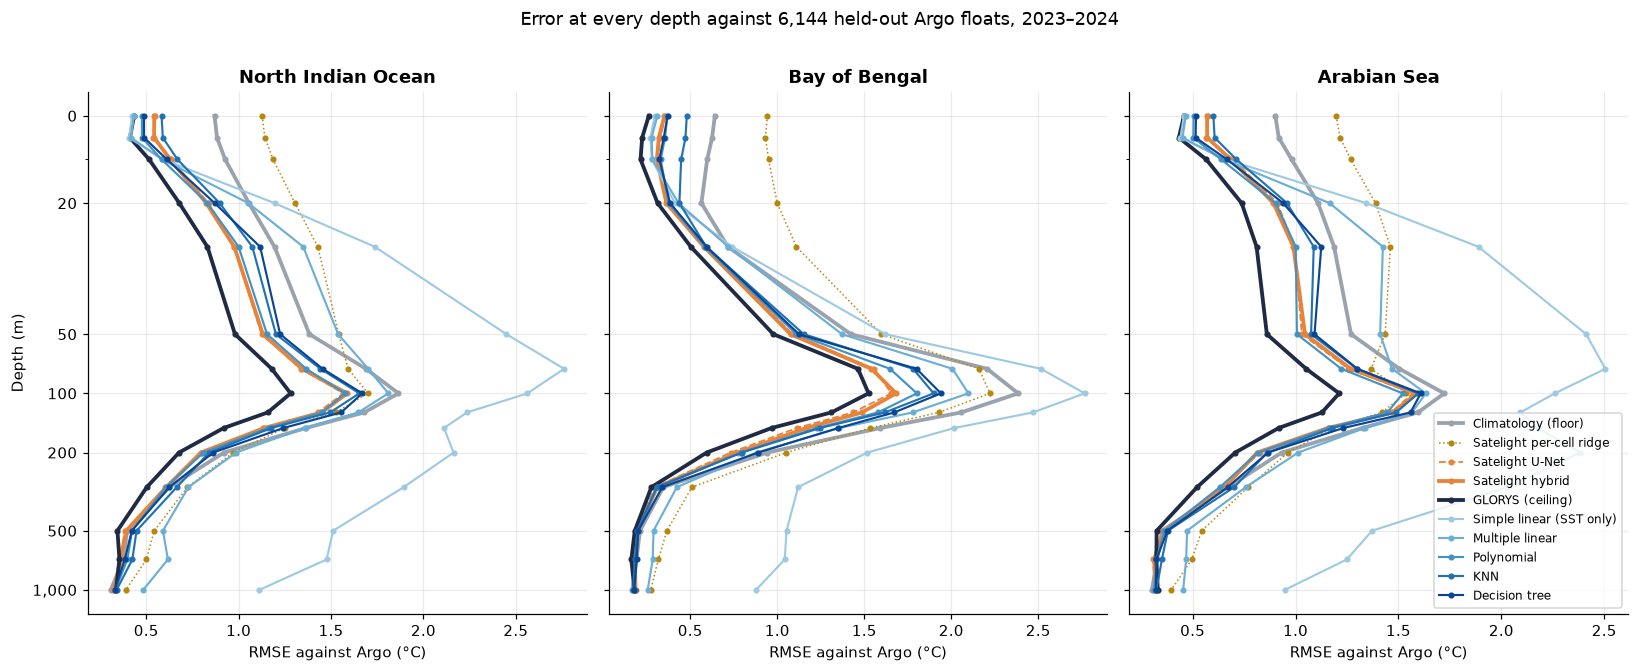

In [8]:
style = {"Climatology (floor)": dict(color=C.PALETTE["climatology"], lw=2.5),
         "GLORYS (ceiling)": dict(color=C.PALETTE["glorys"], lw=2.5),
         "Satelight hybrid": dict(color=C.PALETTE["deep"], lw=2.5),
         "Satelight U-Net": dict(color=C.PALETTE["deep"], lw=1.2, ls="--"),
         "Satelight per-cell ridge": dict(color="#b8860b", lw=1, ls=":")}
course_colors = dict(zip(course, ["#9ecae1", "#6baed6", "#4292c6", "#2171b5", "#084594"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, (r, t) in zip(axes, tables.items()):
    for name in order:
        kw = style.get(name, dict(color=course_colors.get(name), lw=1.4))
        ax.plot(t.loc[name], C.DEPTHS, marker=".", label=name, **kw)
    ax.set_title(r); ax.set_xlabel("RMSE against Argo (°C)")
    ax.set_yscale("symlog", linthresh=50); ax.set_yticks([0, 20, 50, 100, 200, 500, 1000]); ax.set_yticklabels([0, 20, 50, 100, 200, 500, "1,000"])
axes[0].invert_yaxis(); axes[0].set_ylabel("Depth (m)")
axes[2].legend(fontsize=8, loc="lower right")
fig.suptitle("Error at every depth against 6,144 held-out Argo floats, 2023–2024", y=1.01)
fig.tight_layout(); C.save(fig, "regression_rmse_by_depth")

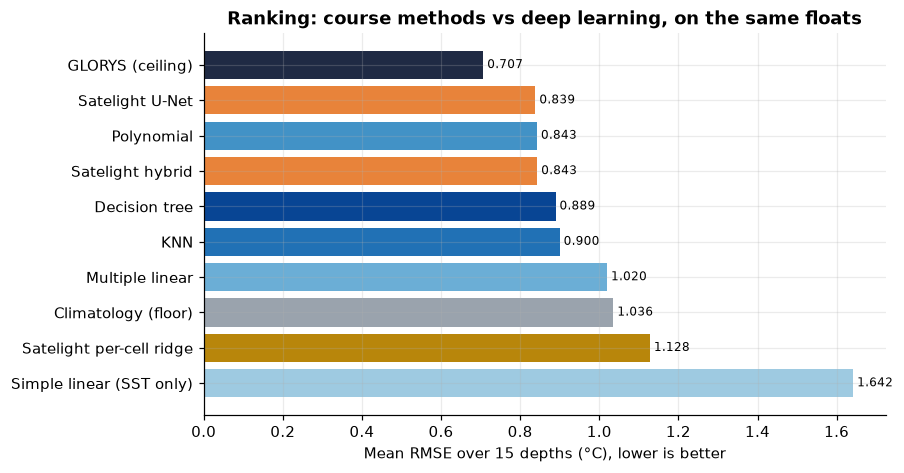

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
s = summ["North Indian Ocean"].sort_values()
colors = [style.get(n, {}).get("color", course_colors.get(n)) for n in s.index]
ax.barh(s.index, s.values, color=colors)
for i, v in enumerate(s.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("Mean RMSE over 15 depths (°C), lower is better")
ax.set_title("Ranking: course methods vs deep learning, on the same floats")
C.save(fig, "regression_ranking")

## 3.4 Why does each model get what it gets? Feature importance

**Permutation importance:** shuffle one input column and measure how much worse the
model gets. If shuffling sea level ruins the prediction at 150 m, then the model relies
on sea level at 150 m. It works for any model, so we use it on the best course method.

,0,50,100,150,300,1000
Sea surface temperature (°C),1.279,0.546,0.136,0.163,0.023,0.026
Sea surface salinity (PSU),0.132,0.956,1.340,1.112,1.049,0.419
"Sea level, absolute (m)",4.108,17.134,6.379,14.889,2.676,3.541
Sea level anomaly (m),0.963,3.773,1.847,3.008,0.994,1.070
"Current, eastward (m/s)",0.002,0.000,0.017,0.020,0.006,0.001
"Current, northward (m/s)",0.003,0.001,0.016,0.018,0.005,0.003
"Wind, eastward (m/s)",0.073,0.058,0.044,0.034,0.020,0.007
"Wind, northward (m/s)",0.029,0.023,0.035,0.021,0.019,0.014
Latitude,0.314,0.754,1.273,1.109,1.224,0.345
Longitude,1.527,2.050,3.882,2.953,3.409,1.343


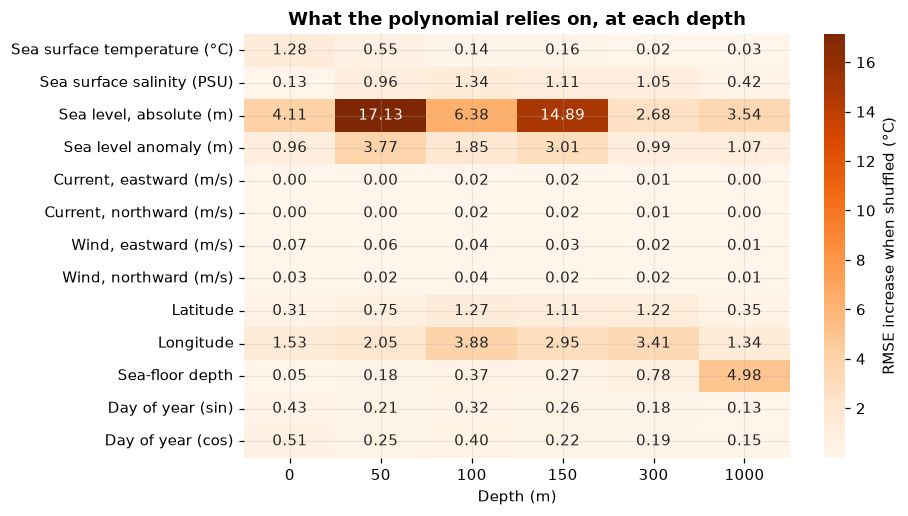

In [10]:
best_course = summ.loc[list(course), "North Indian Ocean"].idxmin()
best_method = {v: k for k, v in LABELS.items()}[best_course]
best_models = fitted[best_method]
sample_test = test.sample(3000, random_state=C.SEED).reset_index(drop=True)
truth = sample_test[C.TARGETS].to_numpy()
base = rmse_by_depth(predict_all(best_models, best_method, sample_test), truth)
rng = np.random.default_rng(C.SEED)
rise = {}
for f in cols_for(best_method):
    runs = []
    for _ in range(3):
        shuffled = sample_test.copy()
        shuffled[f] = rng.permutation(shuffled[f].to_numpy())
        runs.append(rmse_by_depth(predict_all(best_models, best_method, shuffled), truth) - base)
    rise[f] = np.mean(runs, axis=0)
show_depths = [0, 50, 100, 150, 300, 1000]
imp = pd.DataFrame(rise, index=C.DEPTHS).T[show_depths]
imp_named = imp.rename(index={**C.INPUT_NAMES, "lat": "Latitude", "lon": "Longitude", "log_bathy": "Sea-floor depth",
                              "doy_sin": "Day of year (sin)", "doy_cos": "Day of year (cos)"})
C.record("regression.best_course_model", best_course)
C.record("regression.importance", {str(k): v.round(4).to_dict() for k, v in imp.items()})

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(imp_named, annot=True, fmt=".2f", cmap="Oranges", ax=ax, cbar_kws={"label": "RMSE increase when shuffled (°C)"})
ax.set_xlabel("Depth (m)"); ax.set_title(f"What the {best_course.lower()} relies on, at each depth")
C.save(fig, "regression_importance")
imp_named.round(3)

Two cautions on reading this. Shuffling an input of a polynomial model can push it far
outside anything it was trained on, where cubic terms explode, so the *sizes* are
exaggerated; the *ranking* is what to read. And importance shows what the model uses,
not what causes ocean temperature.

## 3.5 What we learn

In [11]:
T = tables["North Indian Ocean"]
facts = {
    "simple_linear_0m": T.loc["Simple linear (SST only)", 0], "satelight_0m": T.loc["Satelight hybrid", 0],
    "glorys_0m": T.loc["GLORYS (ceiling)", 0], "simple_linear_50m": T.loc["Simple linear (SST only)", 50],
    "best_course": best_course, "best_course_mean": summ.loc[best_course, "North Indian Ocean"],
    "satelight_mean": summ.loc["Satelight hybrid", "North Indian Ocean"],
    "top_input_by_depth": imp.idxmax().to_dict(),
}
C.record("regression.facts", facts)
for k, v in facts.items():
    print(f"{k:22s} {v if isinstance(v, (str, dict)) else round(float(v), 3)}")

simple_linear_0m       0.423
satelight_0m           0.543
glorys_0m              0.434
simple_linear_50m      2.449
best_course            Polynomial
best_course_mean       0.843
satelight_mean         0.843
top_input_by_depth     {0: 'adt', 50: 'adt', 100: 'adt', 150: 'adt', 300: 'lon', 1000: 'log_bathy'}


1. **At the surface the simplest model wins.** A straight line from the satellite's sea
   surface temperature beats every other method at 0 m, GLORYS included, because the
   satellite measures that very layer. By 50 m the same line is the worst model on the
   board: the satellite cannot see down there.
2. **Straight lines are not enough below the surface.** Multiple linear regression,
   with all 13 inputs, barely beats climatology. The link between the surface and the
   thermocline bends, and the methods that can bend (polynomial, KNN, tree) close far
   more of the gap.
3. **A cubic polynomial matches the deep model on average.** Over the 15 depths, the
   best course method and Satelight's CNN + transformer hybrid are level. The deep model
   is better in the Bay of Bengal, the polynomial in the Arabian Sea. Chapter 6 tests
   whether any of these differences is real.
4. **Sea level is the key input near the top.** From the surface to 150 m the polynomial
   leans on sea level more than on anything else, which is the physics of chapter 2: warm
   water expands and lifts the sea surface. At 300 m longitude (which sea you are in)
   matters most, and at 1,000 m the sea-floor depth.
5. **The thermocline (75–150 m) is hard for everyone,** GLORYS included. That is
   where the warm layer's lower boundary moves up and down.